In [1]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
Device: cuda


In [2]:

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc = nn.Linear(100, 7 * 7 * 128)

        self.model = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 128, 7, 7)
        return self.model(x)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


generator = Generator().to(device)
discriminator = Discriminator().to(device)

noise = torch.randn(8, 100, device=device)
fake_images = generator(noise)
predictions = discriminator(fake_images)

print("Generator output:", fake_images.shape)
print("Discriminator output:", predictions.shape)
print("GAN architecture test passed!")


Generator output: torch.Size([8, 1, 28, 28])
Discriminator output: torch.Size([8, 1])
GAN architecture test passed!


In [3]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

batch_size = 128

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True
)

print("MNIST dataset downloaded successfully!")
print("Training images:", len(train_dataset))
print("Number of batches:", len(train_loader))


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 343kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.3MB/s]

MNIST dataset downloaded successfully!
Training images: 60000
Number of batches: 468


In [4]:

import torch.optim as optim
import matplotlib.pyplot as plt

criterion = nn.BCELoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

num_epochs = 10

generator.train()
discriminator.train()

for epoch in range(num_epochs):
    total_g_loss = 0
    total_d_loss = 0

    for real_images, _ in train_loader:
        real_images = real_images.to(device)
        batch_size_current = real_images.size(0)

        real_labels = torch.ones(batch_size_current, 1, device=device)
        fake_labels = torch.zeros(batch_size_current, 1, device=device)

        # Train Discriminator
        optimizer_D.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size_current, 100, device=device)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        output = discriminator(fake_images)
        g_loss = criterion(output, real_labels)

        g_loss.backward()
        optimizer_G.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"D Loss: {total_d_loss/len(train_loader):.4f} "
        f"G Loss: {total_g_loss/len(train_loader):.4f}"
    )

print("GAN training completed!")


Epoch [1/10] D Loss: 0.3583 G Loss: 2.4059
Epoch [2/10] D Loss: 0.3360 G Loss: 2.4800
Epoch [3/10] D Loss: 0.3316 G Loss: 2.5522
Epoch [4/10] D Loss: 0.3739 G Loss: 2.4554
Epoch [5/10] D Loss: 0.3832 G Loss: 2.4614
Epoch [6/10] D Loss: 0.3951 G Loss: 2.4751
Epoch [7/10] D Loss: 0.3620 G Loss: 2.5555
Epoch [8/10] D Loss: 0.3551 G Loss: 2.6479
Epoch [9/10] D Loss: 0.3592 G Loss: 2.6815
Epoch [10/10] D Loss: 0.3246 G Loss: 2.8102
GAN training completed!


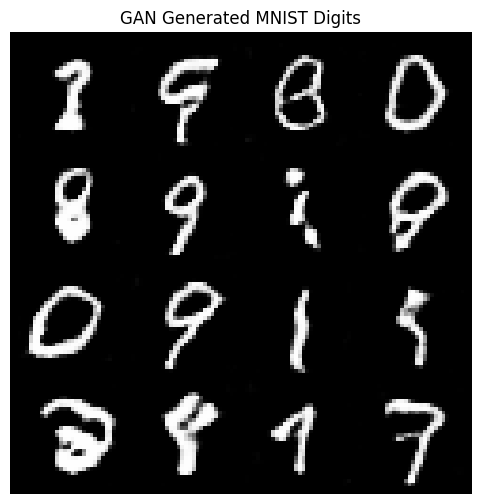

Generator model saved successfully!
Generated images saved successfully!


In [5]:

import matplotlib.pyplot as plt
from torchvision.utils import make_grid

generator.eval()

with torch.no_grad():
    noise = torch.randn(16, 100, device=device)
    generated_images = generator(noise)

images = (generated_images.cpu() + 1) / 2

grid = make_grid(images, nrow=4, padding=2)

plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
plt.axis("off")
plt.title("GAN Generated MNIST Digits")
plt.savefig("generated_digits.png", bbox_inches="tight")
plt.show()

torch.save(generator.state_dict(), "generator.pth")

print("Generator model saved successfully!")
print("Generated images saved successfully!")


In [6]:

from google.colab import files

files.download("generator.pth")
files.download("generated_digits.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

%%writefile main.py
import io
import torch
import torch.nn as nn
from fastapi import FastAPI
from fastapi.responses import StreamingResponse
from torchvision.utils import make_grid
from PIL import Image

app = FastAPI(title="GAN MNIST API")

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(100, 7 * 7 * 128)
        self.model = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 128, 7, 7)
        return self.model(x)

generator = Generator()
generator.load_state_dict(
    torch.load("generator.pth", map_location="cpu", weights_only=True)
)
generator.eval()

@app.get("/")
def home():
    return {"message": "GAN MNIST API is running"}

@app.get("/generate")
def generate():
    with torch.no_grad():
        noise = torch.randn(16, 100)
        images = generator(noise)
        images = (images + 1) / 2
        grid = make_grid(images, nrow=4)

    image = Image.fromarray(
        (grid.permute(1, 2, 0).numpy() * 255).astype("uint8")
    )

    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    buffer.seek(0)

    return StreamingResponse(buffer, media_type="image/png")


Writing main.py


In [8]:

%%writefile requirements.txt
fastapi
uvicorn
torch
torchvision
pillow


Writing requirements.txt


In [9]:

%%writefile Dockerfile
FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY main.py .
COPY generator.pth .

EXPOSE 8000

CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]


Writing Dockerfile


In [10]:

%pip install -q fastapi uvicorn httpx


Home endpoint status: 200
Home response: {'message': 'GAN MNIST API is running'}
Generate endpoint status: 200
Content type: image/png


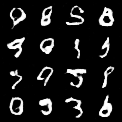

FastAPI GAN test passed!


In [11]:

import subprocess
import time
import requests
from IPython.display import display, Image as IPImage

server = subprocess.Popen(
    ["uvicorn", "main:app", "--host", "127.0.0.1", "--port", "8000"],
    stdout=open("server.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8000/", timeout=15)
    print("Home endpoint status:", response.status_code)
    print("Home response:", response.json())

    response = requests.get("http://127.0.0.1:8000/generate", timeout=30)
    print("Generate endpoint status:", response.status_code)
    print("Content type:", response.headers.get("content-type"))

    if response.status_code == 200:
        display(IPImage(data=response.content))
        print("FastAPI GAN test passed!")
    else:
        print(response.text)

except Exception as e:
    print("API test error:", e)
    print(open("server.log").read())


In [12]:

import os
import zipfile
from google.colab import files

project_files = [
    "main.py",
    "requirements.txt",
    "Dockerfile",
    "generator.pth",
    "generated_digits.png"
]

with zipfile.ZipFile("Assignment3_GAN_Project.zip", "w") as zipf:
    for filename in project_files:
        if not os.path.isfile(filename):
            raise FileNotFoundError(filename)
        zipf.write(filename)

print("Project ZIP created successfully!")
print("Files included:", project_files)

files.download("Assignment3_GAN_Project.zip")


Project ZIP created successfully!
Files included: ['main.py', 'requirements.txt', 'Dockerfile', 'generator.pth', 'generated_digits.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>